# Activation Functions Benchmark

**A controlled PyTorch study of Sigmoid, Tanh, ReLU, and LeakyReLU in a deep MLP.**

This notebook reproduces the repository experiment end to end: it builds the data,
verifies the initialization controls, trains 20 models, aggregates the results, and
renders the same figures used in the README.

- **20 runs** — four activations x five seeds
- **150 epochs** per run
- **2,241 parameters** in the shared architecture
- **Same initial weights** per seed across activations

> Runtime is about 30–60 seconds on a modern CPU. The notebook writes temporary
> figures to <code>results/notebook_figures/</code> and does not overwrite the
> canonical <code>results/results.json</code>.

## 1. Setup

The package lives under <code>src/</code>. The path logic below works whether the
notebook is launched from the repository root or from the <code>notebooks/</code>
directory.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
sys.path.insert(0, str(ROOT / "src"))

from activation_benchmark.analysis import (
    as_records,
    load_results,
    statistical_tests,
    summarize,
)
from activation_benchmark.config import ACTIVATIONS, ExperimentConfig
from activation_benchmark.data import load_moons
from activation_benchmark.models import build_mlp, count_parameters
from activation_benchmark.plotting import make_all_figures, plot_activation_shapes
from activation_benchmark.training import run_experiment

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})

FIG_DIR = ROOT / "results" / "notebook_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Repository root: {ROOT}")
print(f"PyTorch: {torch.__version__}")

Repository root: C:\Users\alijo\OneDrive\Desktop\deep learn\_work\repo\activation-functions-benchmark
PyTorch: 2.14.1+cpu


## 2. Data

Two moons, 600 samples, noise 0.22. The split is stratified 70/30, and the scaler is
fitted on the training set only. The plot below is in the original feature space; the
model sees standardized features.

In [2]:
config = ExperimentConfig()
data = load_moons(config)

print(f"Train: {data.X_train.shape[0]} examples")
print(f"Test:  {data.X_test.shape[0]} examples")
print(f"Train class balance: {np.bincount(data.y_train.astype(int)).tolist()}")
print(f"Test class balance:  {np.bincount(data.y_test.astype(int)).tolist()}")
print(f"Train feature mean after scaling: {data.X_train.mean(axis=0).round(6)}")

Train: 420 examples
Test:  180 examples
Train class balance: [210, 210]
Test class balance:  [90, 90]
Train feature mean after scaling: [-0.  0.]


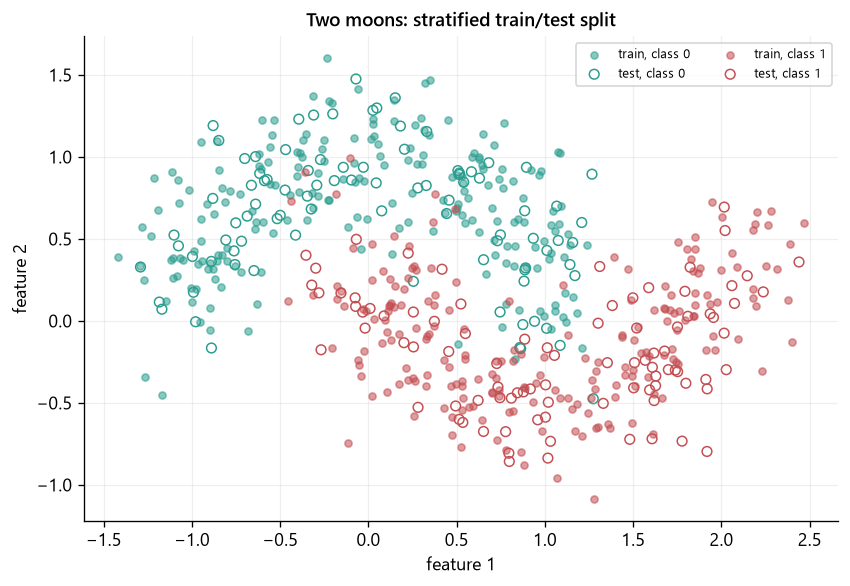

In [3]:
X_train_raw = data.scaler.inverse_transform(data.X_train)
X_test_raw = data.scaler.inverse_transform(data.X_test)

fig, ax = plt.subplots(figsize=(7.2, 5.0))
for label, color, name in [(0, "#2A9D8F", "class 0"), (1, "#C44E52", "class 1")]:
    ax.scatter(
        X_train_raw[data.y_train == label, 0],
        X_train_raw[data.y_train == label, 1],
        s=18,
        alpha=0.55,
        color=color,
        label=f"train, {name}",
    )
    ax.scatter(
        X_test_raw[data.y_test == label, 0],
        X_test_raw[data.y_test == label, 1],
        s=34,
        facecolors="none",
        edgecolors=color,
        linewidths=0.9,
        label=f"test, {name}",
    )
ax.set(xlabel="feature 1", ylabel="feature 2", title="Two moons: stratified train/test split")
ax.legend(fontsize=8, ncol=2, loc="upper right", frameon=True)
plt.tight_layout()
display(fig)

## 3. Model and controls

The architecture is <code>2 -> 32 -> 32 -> 32 -> 1</code>. Every activation gets the
same Xavier-uniform initial weights for a given seed, so the comparison is not
confounded by initialization luck.

In [4]:
models = {
    name: build_mlp(name, seed=0, widths=config.widths)
    for name in ACTIVATIONS
}

reference = [p.detach().clone() for p in models["Sigmoid"].parameters()]
rows = []
for name, model in models.items():
    identical = all(
        torch.equal(p.detach(), ref)
        for p, ref in zip(model.parameters(), reference, strict=True)
    )
    rows.append(
        {
            "activation": name,
            "parameters": count_parameters(model),
            "same init as Sigmoid": identical,
        }
    )

display(pd.DataFrame(rows).set_index("activation"))

,parameters,same init as Sigmoid
activation,,
Sigmoid,2241,True
Tanh,2241,True
ReLU,2241,True
LeakyReLU,2241,True


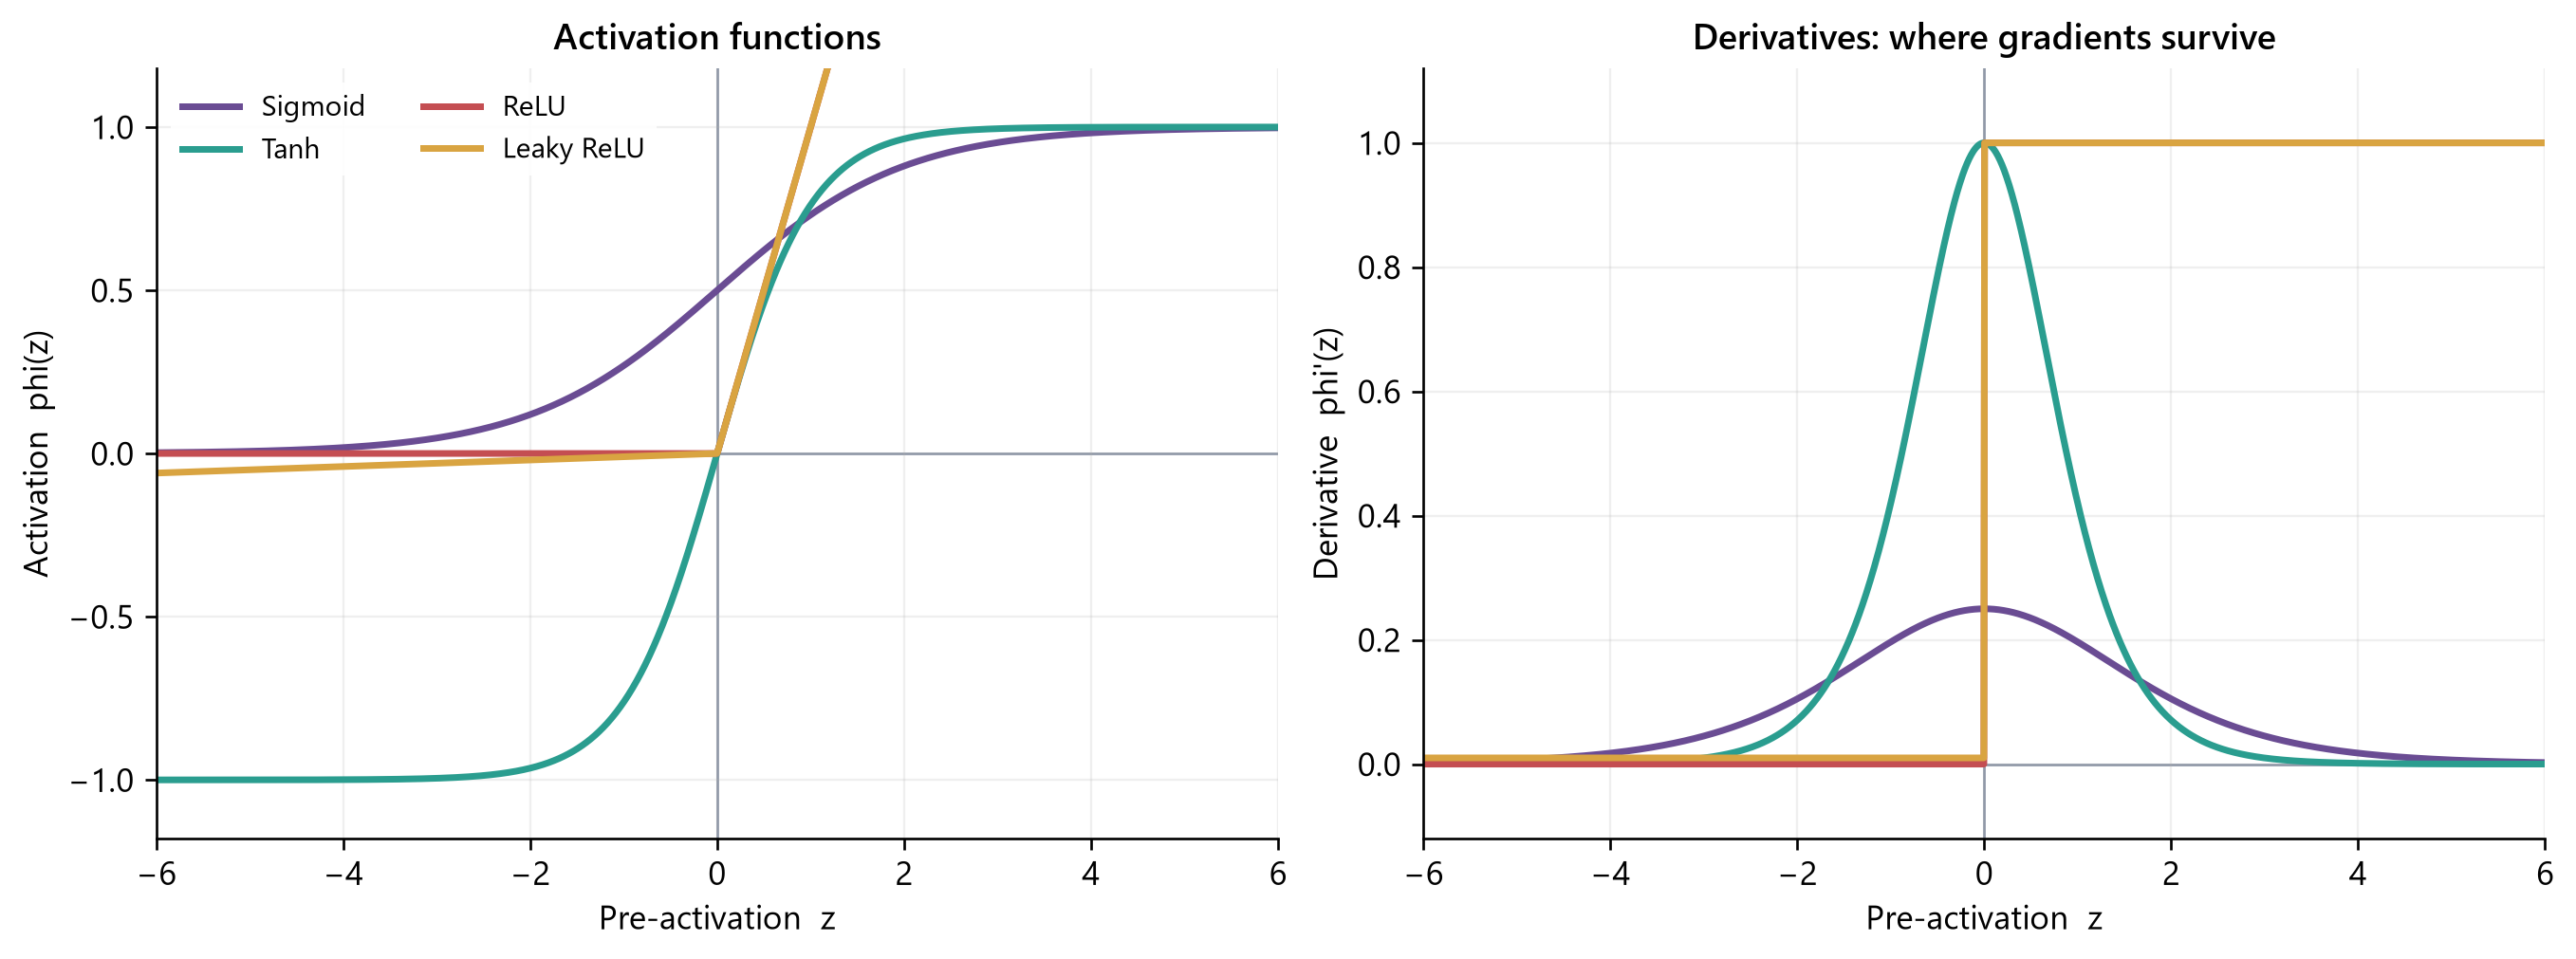

In [5]:
shapes_path = plot_activation_shapes(FIG_DIR / "activation_shapes.png")
display(Image(filename=str(shapes_path)))

## 4. Train the sweep

Four activations x five seeds. Progress is printed per run; the full histories are
kept in memory for the plots and the per-seed table.

In [6]:
started = time.perf_counter()
results = run_experiment(config, progress=True)
elapsed = time.perf_counter() - started
print(f"\nFinished {len(results)} runs in {elapsed:.2f} seconds")

Sigmoid    seed=0  test_acc=0.9444  train_loss=0.1359  convergence=64


Sigmoid    seed=1  test_acc=0.9556  train_loss=0.1434  convergence=60


Sigmoid    seed=2  test_acc=0.9444  train_loss=0.1519  convergence=27


Sigmoid    seed=3  test_acc=0.9556  train_loss=0.1399  convergence=35


Sigmoid    seed=4  test_acc=0.9556  train_loss=0.1457  convergence=58


Tanh       seed=0  test_acc=0.9611  train_loss=0.1243  convergence=5


... (11 outputs left out)

LeakyReLU  seed=2  test_acc=0.9611  train_loss=0.0919  convergence=3


LeakyReLU  seed=3  test_acc=0.9611  train_loss=0.0832  convergence=4


LeakyReLU  seed=4  test_acc=0.9444  train_loss=0.0884  convergence=3



Finished 20 runs in 27.78 seconds


## 5. Aggregate results

Means and sample standard deviations across seeds. Accuracy is shown as a fraction;
multiply by 100 for percent.

In [7]:
summary = summarize(results)
display(summary.round(4))

,activation,test_accuracy_mean,test_accuracy_sd,train_accuracy_mean,train_loss_mean,test_loss_mean,convergence_epoch_mean,first_layer_grad_norm_last10_mean,dead_fraction_mean,saturated_fraction_mean,epoch_time_ms_mean
0,Sigmoid,0.9511,0.0061,0.9514,0.1434,0.1390,48.8,0.0641,0.0000,0.0125,8.4646
1,Tanh,0.9578,0.0030,0.9581,0.1158,0.1430,6.6,0.1729,0.0000,0.0680,8.5043
2,ReLU,0.9456,0.0173,0.9600,0.0982,0.1751,3.6,0.2386,0.1375,0.0000,8.5392
3,LeakyReLU,0.9556,0.0079,0.9638,0.0909,0.1751,3.6,0.2354,0.0000,0.0000,8.4806


In [8]:
tests = statistical_tests(results)
print(
    f"One-way ANOVA:     F = {tests['anova_F']:.4f}, p = {tests['anova_p']:.4f}"
)
print(
    f"Kruskal-Wallis:    H = {tests['kruskal_H']:.4f}, p = {tests['kruskal_p']:.4f}"
)
print(f"Seeds per group:   {int(tests['n_per_group'])}")

canonical = summarize(load_results(ROOT / "results" / "results.json"))
fresh = summary.set_index("activation")["test_accuracy_mean"]
committed = canonical.set_index("activation")["test_accuracy_mean"]
max_diff = float((fresh - committed).abs().max())
print(f"Max accuracy difference vs committed artifact: {max_diff:.2e}")

One-way ANOVA:     F = 1.4293, p = 0.2711
Kruskal-Wallis:    H = 4.1187, p = 0.2489
Seeds per group:   5
Max accuracy difference vs committed artifact: 0.00e+00


## 6. Learning curves and convergence

The left panel shows mean training BCE with ±1 s.d. bands. The right panel shows the
first-layer gradient norm, smoothed with a 5-epoch moving average and plotted on a
log scale.

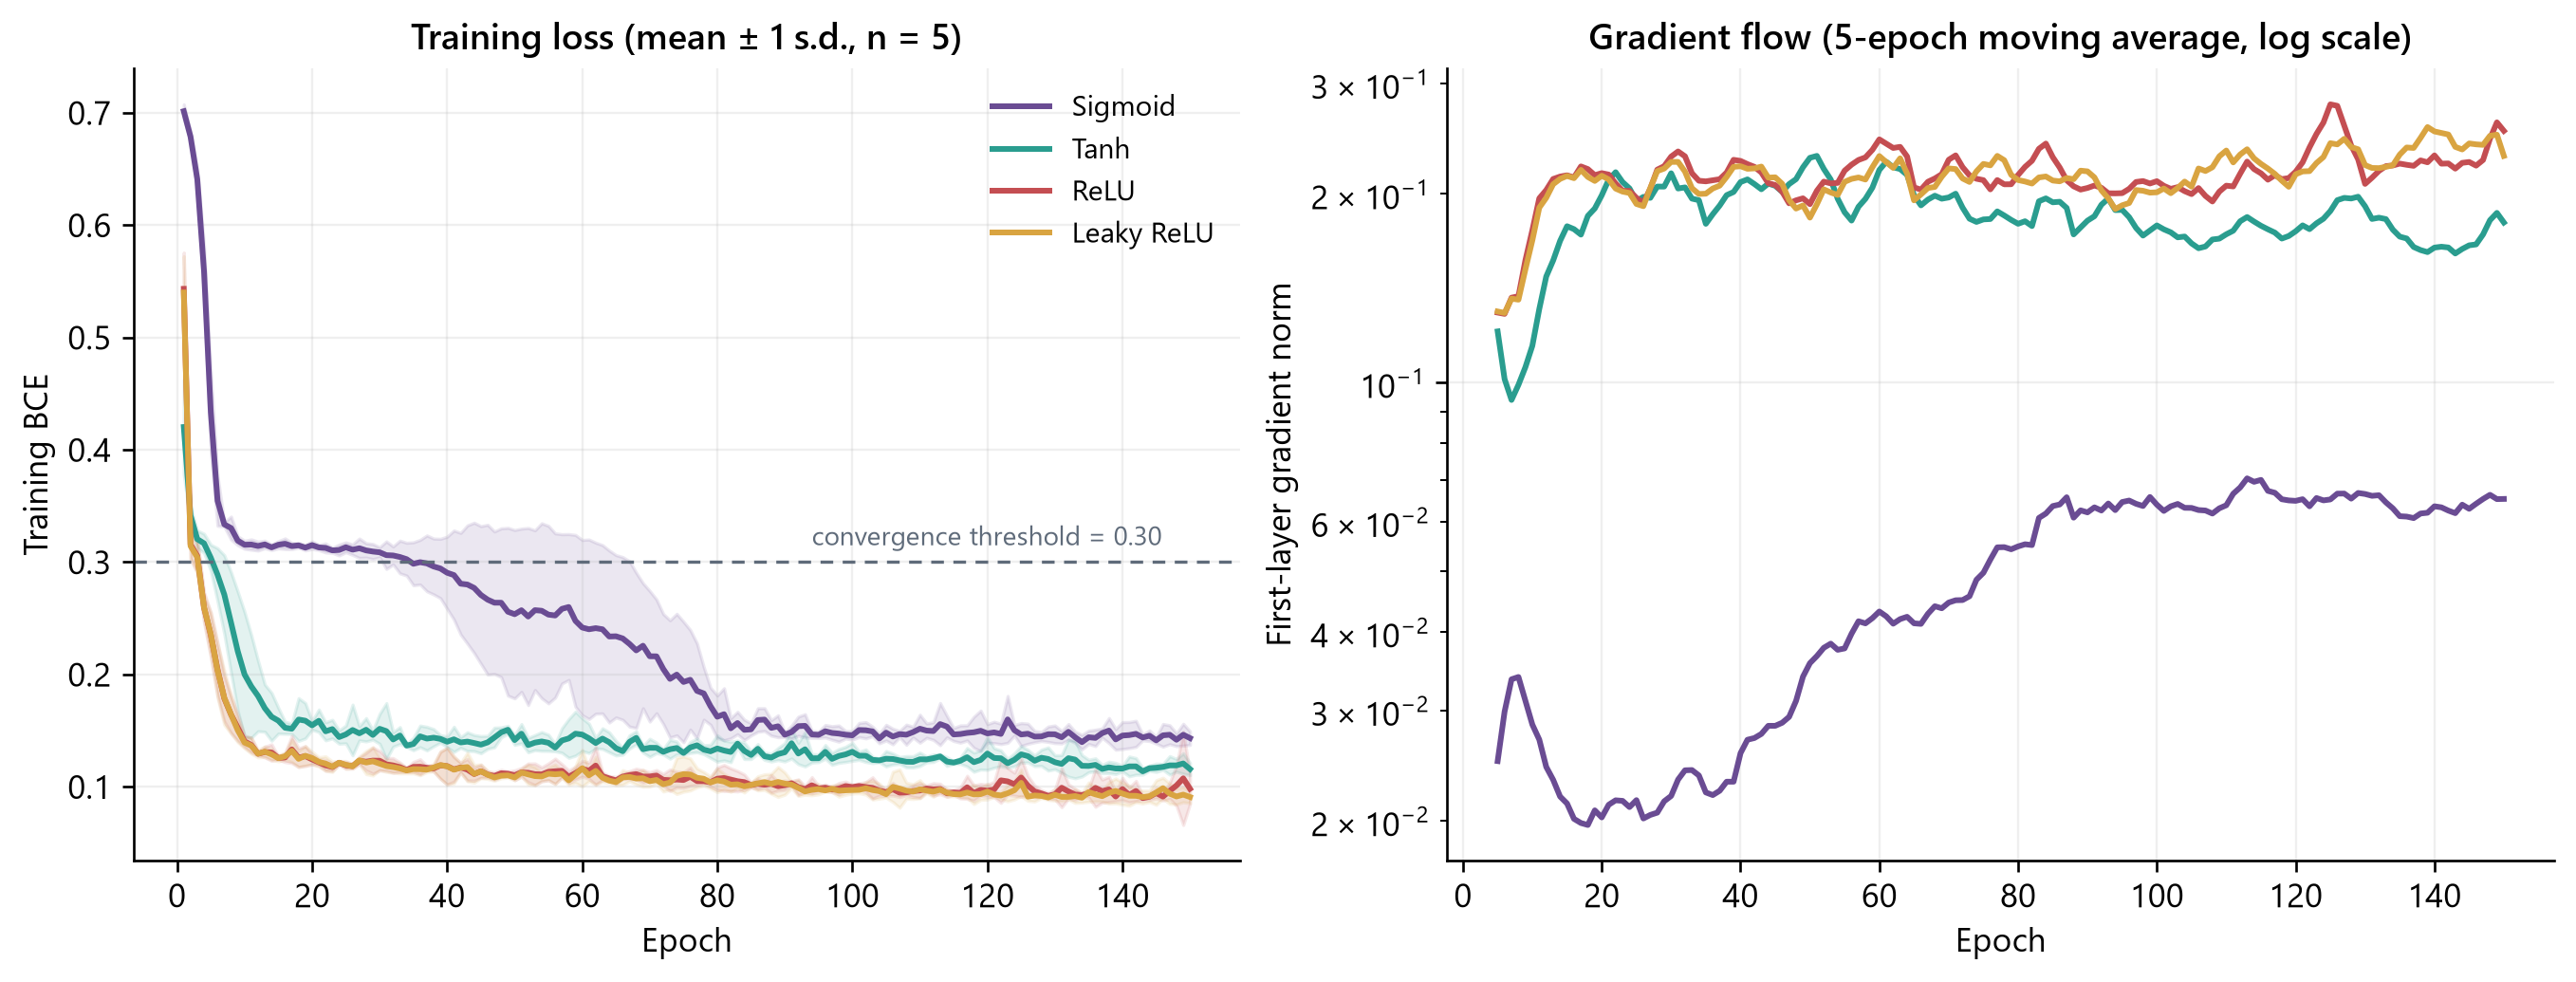

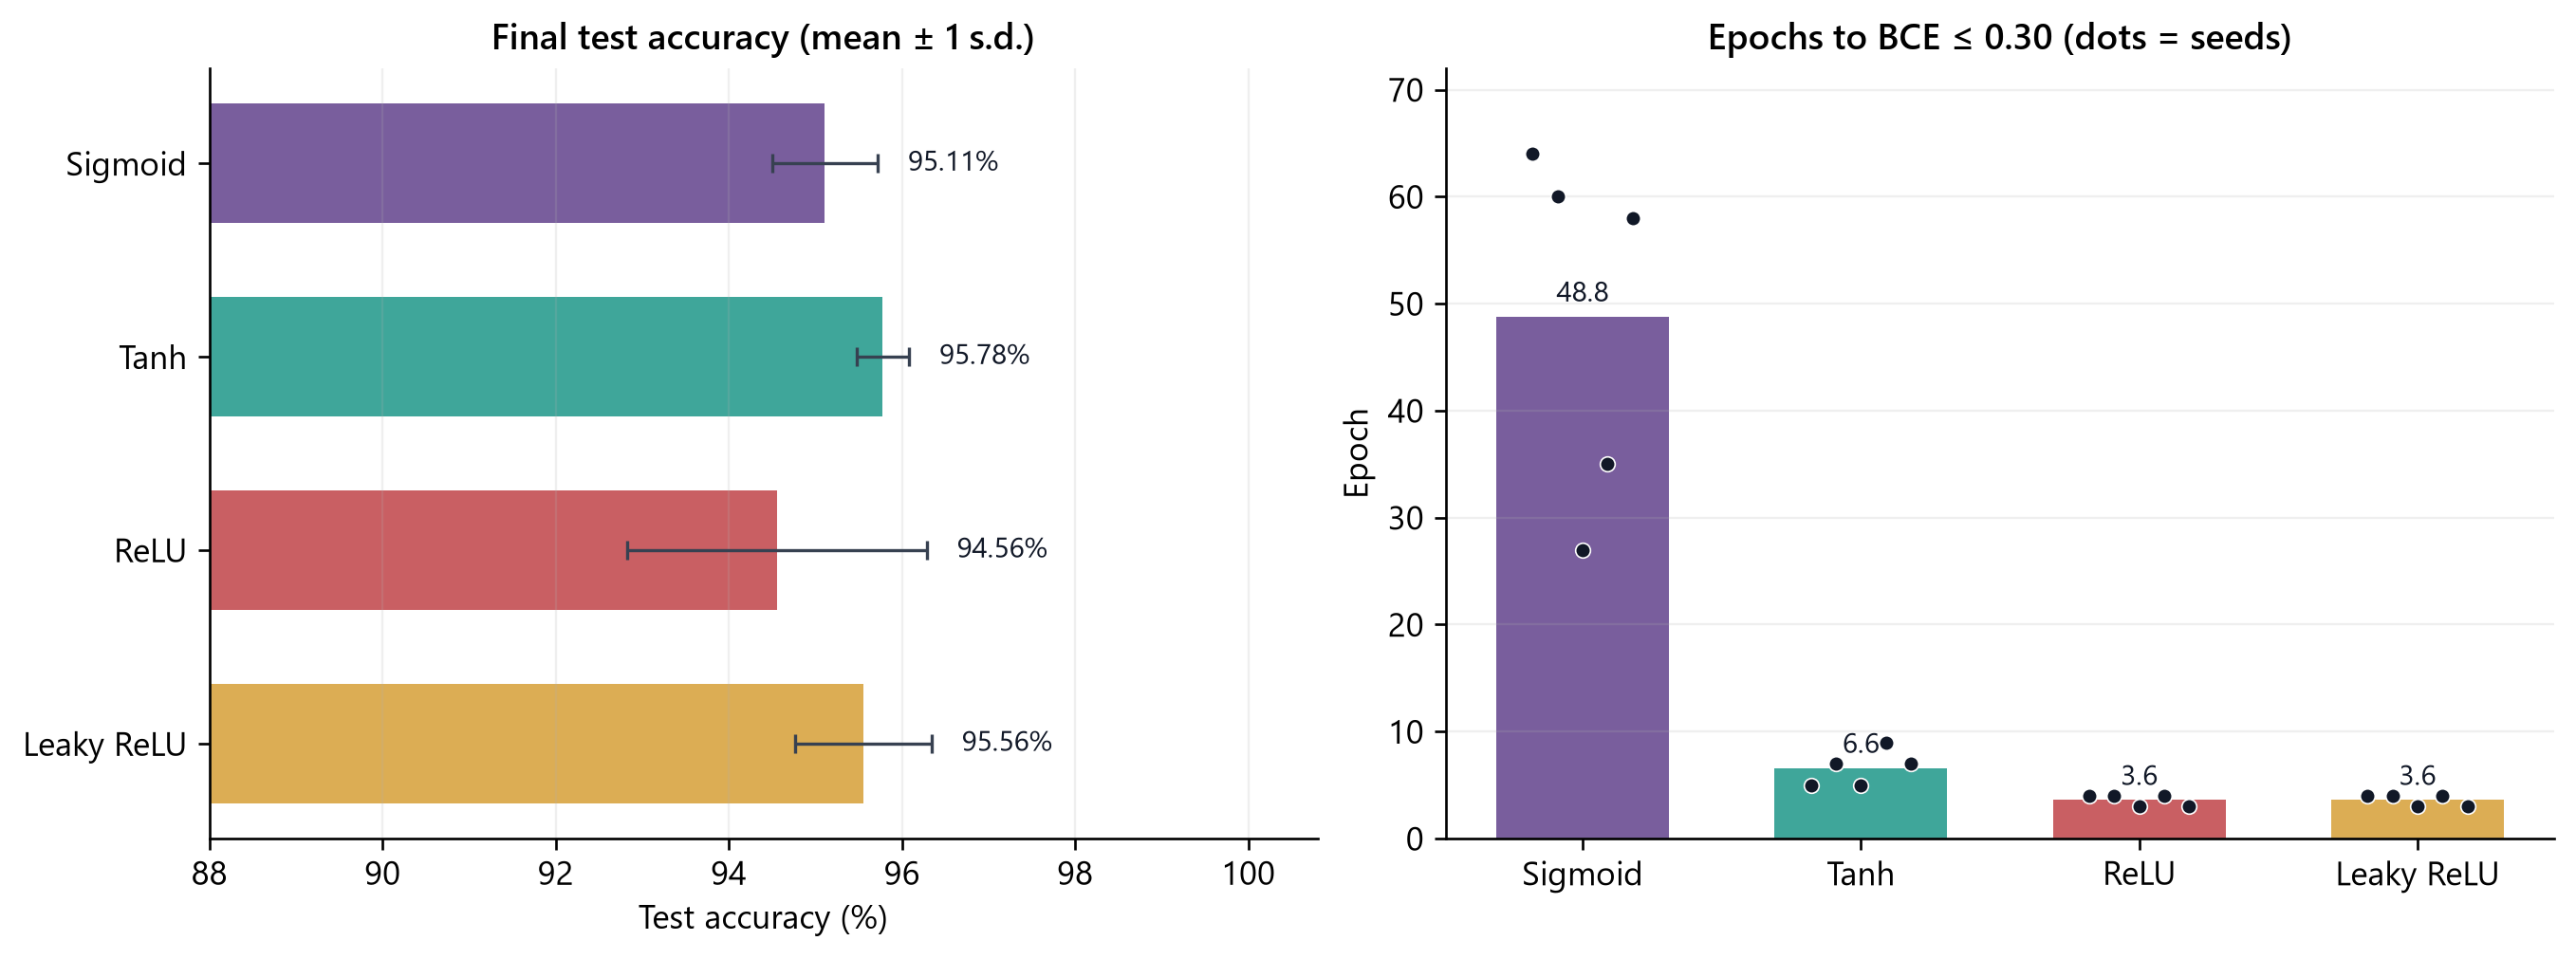

In [9]:
figures = make_all_figures(results, FIG_DIR)
display(Image(filename=str(figures["training_dynamics"])))
display(Image(filename=str(figures["accuracy_convergence"])))

## 7. Hidden-unit health

Dead units are ReLU outputs that never activate on the training set. Saturated units
are Sigmoid/Tanh outputs in the flat tail. ReLU trades dead units for speed;
LeakyReLU avoids the failure mode with a 0.01 negative slope.

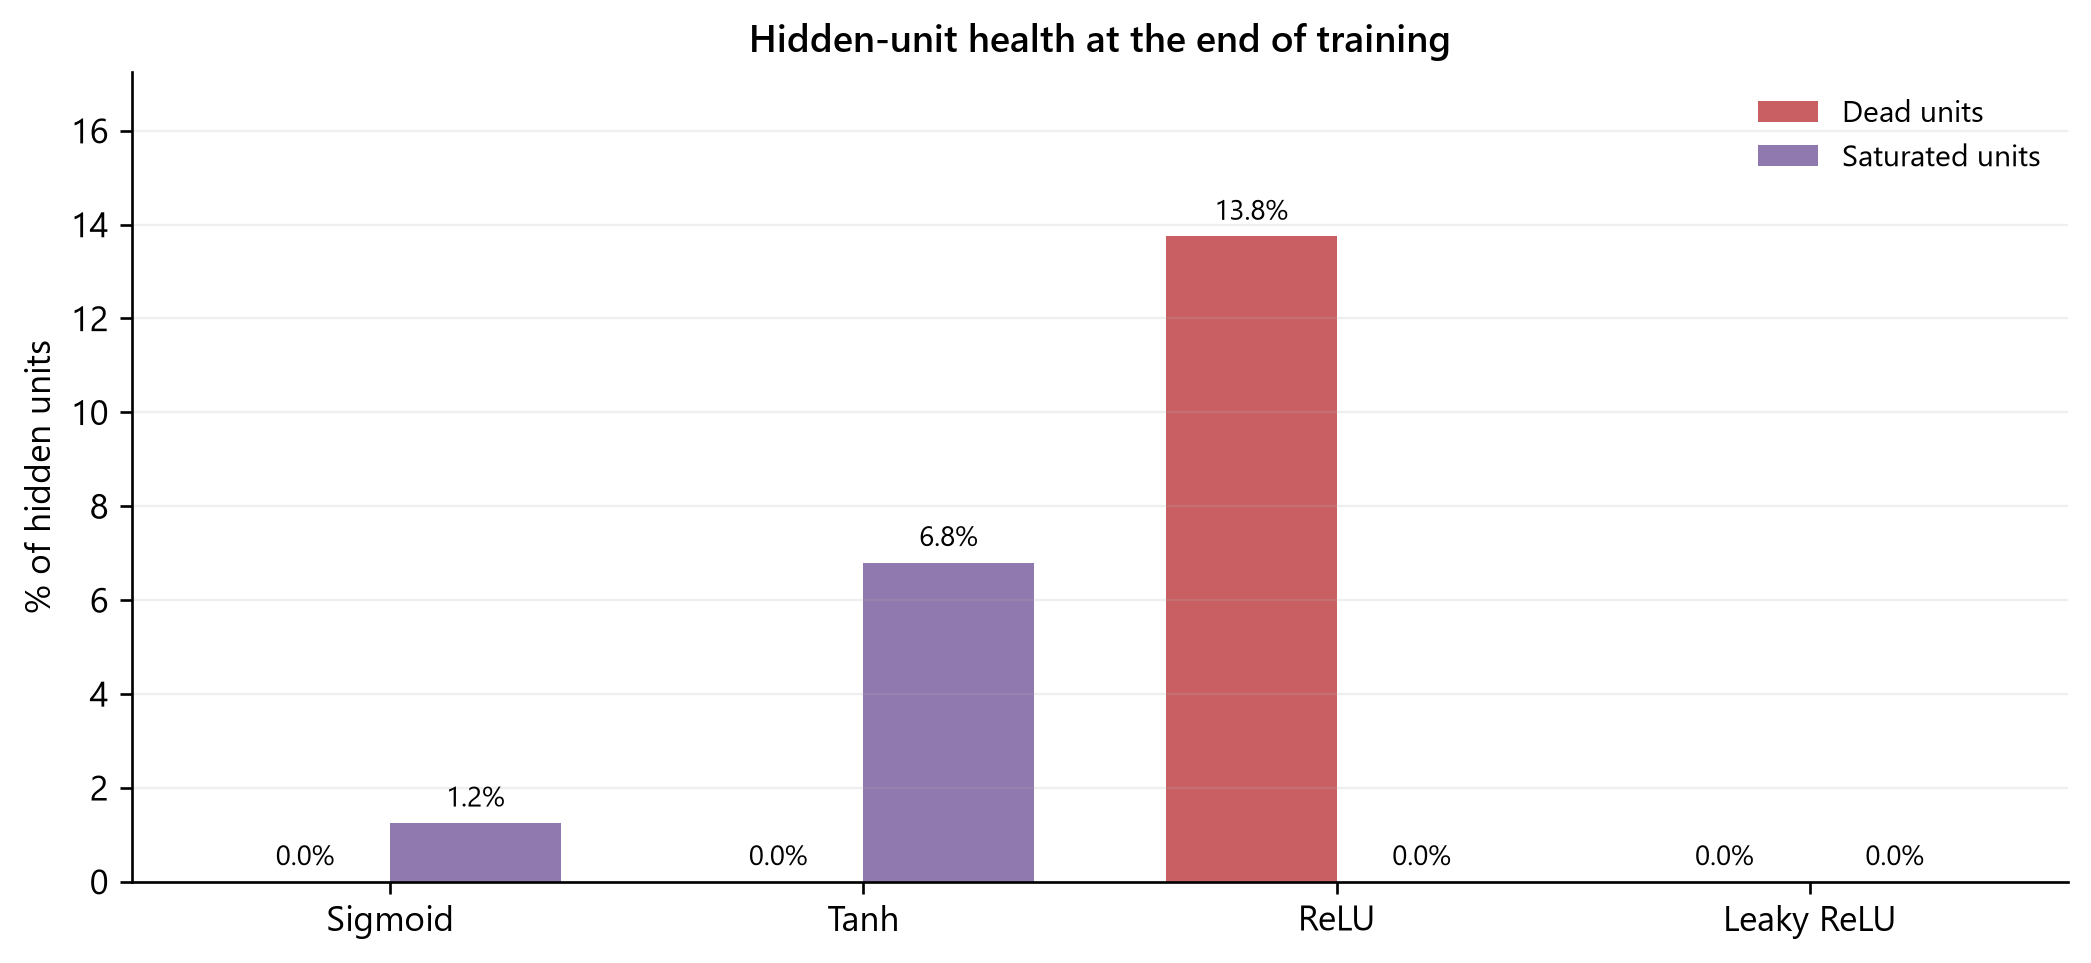

In [10]:
display(Image(filename=str(figures["health_profile"])))

## 8. Per-seed results

The aggregate table can hide seed-level instability. This is the full record behind
the summary.

In [11]:
per_seed = pd.DataFrame(
    [
        {
            "activation": r.activation,
            "seed": r.seed,
            "test_accuracy": round(r.test_accuracy * 100, 2),
            "train_loss": round(r.final_train_loss, 4),
            "test_loss": round(r.final_test_loss, 4),
            "convergence_epoch": r.convergence_epoch,
            "grad_norm": round(r.first_layer_grad_norm_last10, 4),
            "dead_%": round(r.dead_fraction * 100, 2),
            "saturated_%": round(r.saturated_fraction * 100, 2),
        }
        for r in results
    ]
).sort_values(["activation", "seed"], ignore_index=True)
display(per_seed)

,activation,seed,test_accuracy,train_loss,test_loss,convergence_epoch,grad_norm,dead_%,saturated_%
0,LeakyReLU,0,96.11,0.0981,0.1575,4,0.2205,0.00,0.00
1,LeakyReLU,1,95.00,0.0930,0.1542,4,0.2776,0.00,0.00
2,LeakyReLU,2,96.11,0.0919,0.1703,3,0.2214,0.00,0.00
3,LeakyReLU,3,96.11,0.0832,0.1880,4,0.2267,0.00,0.00
4,LeakyReLU,4,94.44,0.0884,0.2057,3,0.2310,0.00,0.00
5,ReLU,0,95.56,0.0998,0.1795,4,0.2192,16.67,0.00
6,ReLU,1,95.00,0.0904,0.1521,4,0.2230,17.71,0.00
7,ReLU,2,91.67,0.1209,0.1815,3,0.3520,10.42,0.00
8,ReLU,3,96.11,0.0926,0.1653,4,0.1735,15.62,0.00
9,ReLU,4,94.44,0.0875,0.1971,3,0.2252,8.33,0.00


## 9. What the numbers say

1. **Nonlinearity was not the accuracy bottleneck.** All four activations finished
   above 94.5%, and the ANOVA did not reject equality of means (p ≈ 0.27).
2. **ReLU-family wins the race.** ReLU and LeakyReLU crossed the 0.30 BCE threshold in
   3.6 epochs on average, versus 48.8 for Sigmoid and 6.6 for Tanh.
3. **Sigmoid is slow because gradients shrink.** Its final first-layer gradient norm
   was 0.064 versus 0.239 for ReLU.
4. **Tanh is the quiet overachiever.** It had the best mean accuracy (95.78% ± 0.30%)
   and the smallest seed variance, but still saturated 6.80% of hidden units.
5. **Dead units are a ReLU tax.** ReLU left 13.75% of hidden units dead; LeakyReLU
   left 0% and matched its convergence speed.

These are observations from one dataset and one architecture, not universal laws.
See <code>docs/METHODOLOGY.md</code> for the threats to validity.

## 10. Reproduce from the command line

The notebook and the CLI share the same code path. From the repository root:

~~~bash
pip install -e ".[dev]"
activation-benchmark run --epochs 150 --seeds 5 --output-dir results
activation-benchmark figures --results results/results.json --output-dir results/figures
~~~

To execute this notebook non-interactively:

~~~bash
jupyter nbconvert --to notebook --execute notebooks/activation_functions_benchmark.ipynb --inplace
~~~